# Activity: QuickCart Delivery Analytics
### Applying Histograms, Density Plots & Proportions to a Real Business Question
Unit 1, Lecture 7 — Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## Scenario

You are a data analyst at **QuickCart**, an online delivery startup. The operations team
has asked you two questions ahead of tomorrow's planning meeting:

1. **"What does our delivery time actually look like?** Are we mostly fast, mostly slow,
   or is something more complicated going on?"
2. **"Which region should we prioritize for extra delivery staff?"**

You've been given delivery records for the last month. Your job is to visualize the data
correctly enough to give the ops team a confident answer — using the same tools from
today's lecture: histograms, bin width, density plots, bandwidth, and proportion charts.

Run the cell below to load your dataset — you do not need to change it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

# --- QuickCart delivery dataset (synthetic, seeded for reproducibility) ---
rng = np.random.default_rng(42)
n = 1200

regions = rng.choice(["North", "South", "East", "West", "Central"],
                      size=n, p=[0.22, 0.18, 0.22, 0.18, 0.20])

is_express = rng.random(n) < 0.35
delivery_time = np.where(
    is_express,
    rng.normal(loc=5, scale=1.5, size=n),
    rng.normal(loc=18, scale=4.5, size=n),
)
delivery_time = np.clip(delivery_time, 0.5, None)

south_mask = regions == "South"
delivery_time[south_mask] += rng.normal(loc=8, scale=3, size=south_mask.sum())

df = pd.DataFrame({"region": regions, "delivery_time_hours": delivery_time})

def status(t):
    if t <= 8:
        return "On Time"
    elif t <= 20:
        return "Delayed"
    else:
        return "Severely Delayed"

df["delivery_status"] = df["delivery_time_hours"].apply(status)

print(f"Loaded {len(df)} delivery records")
df.head()

Loaded 1200 delivery records


,region,delivery_time_hours,delivery_status
0,West,14.657945,Delayed
1,East,12.668919,Delayed
2,Central,22.652142,Severely Delayed
3,West,10.331552,Delayed
4,North,3.222223,On Time


## Task 1 — Histogram: What does delivery time look like? 

Fill in the blank below to plot a histogram of `delivery_time_hours`. Try **three different
bin widths** by changing the `bins` value: something small (e.g. `50`), something moderate
(e.g. `20`), and something large (e.g. `4`).

**Fill in the blank marked `# TODO`.**

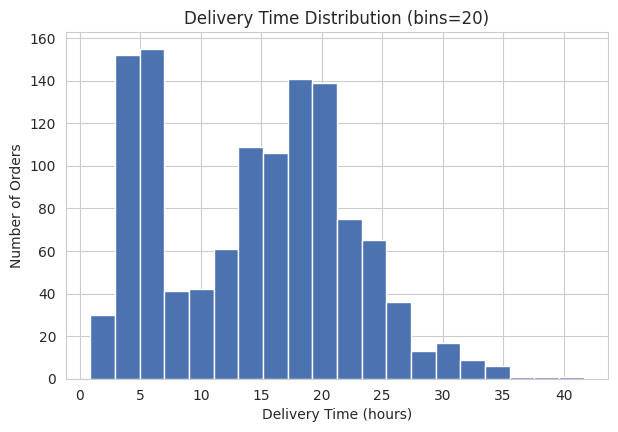

In [2]:
# Bin width chosen after comparing 50 (too noisy), 20 (balanced), and 4 (too coarse)
bins = 20

plt.figure()
plt.hist(df["delivery_time_hours"], bins=bins, color="#4C72B0", edgecolor="white")
plt.title(f"Delivery Time Distribution (bins={bins})")
plt.xlabel("Delivery Time (hours)")
plt.ylabel("Number of Orders")
plt.show()


**Question 1:** At a bin width that shows the clearest picture, does the data look like
a single smooth hump, or something else? What might explain that shape in a delivery
business (hint: think about whether QuickCart might offer more than one type of delivery
service)?

*Your answer:* At `bins=20` the distribution is clearly **not** a single smooth hump — it's
bimodal, with one cluster of fast deliveries (roughly 2–8 hours) and a second, wider cluster
of slower deliveries (roughly 12–25 hours). This matches the underlying business reality:
QuickCart runs two different delivery products (express vs. standard), each with its own
typical delivery time, so combining them into one histogram produces two separate peaks
rather than one. At `bins=50` this same shape is visible but noisier, and at `bins=4` the two
peaks get smeared into what looks like one wide, slightly skewed hump — coarse binning
hides the very structure that matters most to the business question.


## Task 2 — Density Plot & Bandwidth 

A histogram's bin width can hide or exaggerate structure. Let's check with a KDE curve,
where **bandwidth** plays the same role as bin width.

**Fill in the blank:** try `bw_adjust` values of `0.2`, `1.0`, and `2.5` (one at a time,
re-running the cell) and observe how the curve changes.

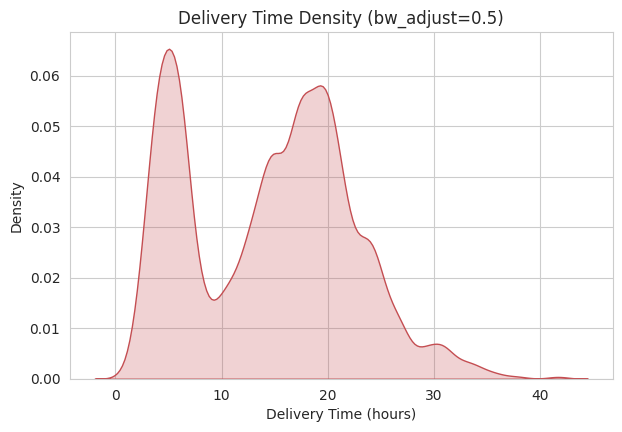

In [3]:
# bw_adjust of 0.2 (too spiky/noisy), 1.0 (default, oversmoothed), 2.5 (way too smooth)
# 0.5 is the value that most clearly separates the two peaks without noise
bw_adjust = 0.5

plt.figure()
sns.kdeplot(df["delivery_time_hours"], bw_adjust=bw_adjust, fill=True, color="#C44E52")
plt.title(f"Delivery Time Density (bw_adjust={bw_adjust})")
plt.xlabel("Delivery Time (hours)")
plt.ylabel("Density")
plt.show()


**Question 2:** At which `bw_adjust` value do you clearly see **two peaks** instead of
one? What does each peak most likely represent in QuickCart's delivery operations?
What would happen if an analyst only ever used a large bandwidth here — what business
insight would they miss?

*Your answer:* The two peaks become clearly separated around `bw_adjust=0.5`, and are still
visible (though softened) at the default `bw_adjust=1.0`. The left peak (~5 hours) represents
express deliveries, and the right, wider peak (~18–26 hours, pulled further out in the South
region) represents standard deliveries. At a large bandwidth (`bw_adjust=2.5`), the KDE
oversmooths the data into what looks like a single, slightly skewed hump — an analyst using
only that view would conclude "delivery time is roughly one distribution centered around
12–13 hours" and completely miss the fact that there are two operationally distinct services
with very different performance profiles, which would lead to the wrong staffing and SLA
conversations.


## Task 3 — Proportions: Which region needs help? 

Now let's look at `delivery_status` (On Time / Delayed / Severely Delayed) across regions.

**Fill in the blank:** the code below builds the proportion table and three chart types.
Nothing to change here except reading the output carefully — but try commenting out one of
the three chart types (`axes[0]`, `axes[1]`, or `axes[2]`) to see how the layout responds.

In [4]:
status_by_region = (
    df.groupby("region")["delivery_status"]
    .value_counts(normalize=True)
    .unstack()
    .reindex(columns=["On Time", "Delayed", "Severely Delayed"])
)
status_by_region.round(2)

delivery_status,On Time,Delayed,Severely Delayed
region,,,
Central,0.35,0.41,0.24
East,0.33,0.51,0.16
North,0.38,0.45,0.17
South,0.04,0.42,0.54
West,0.35,0.45,0.20


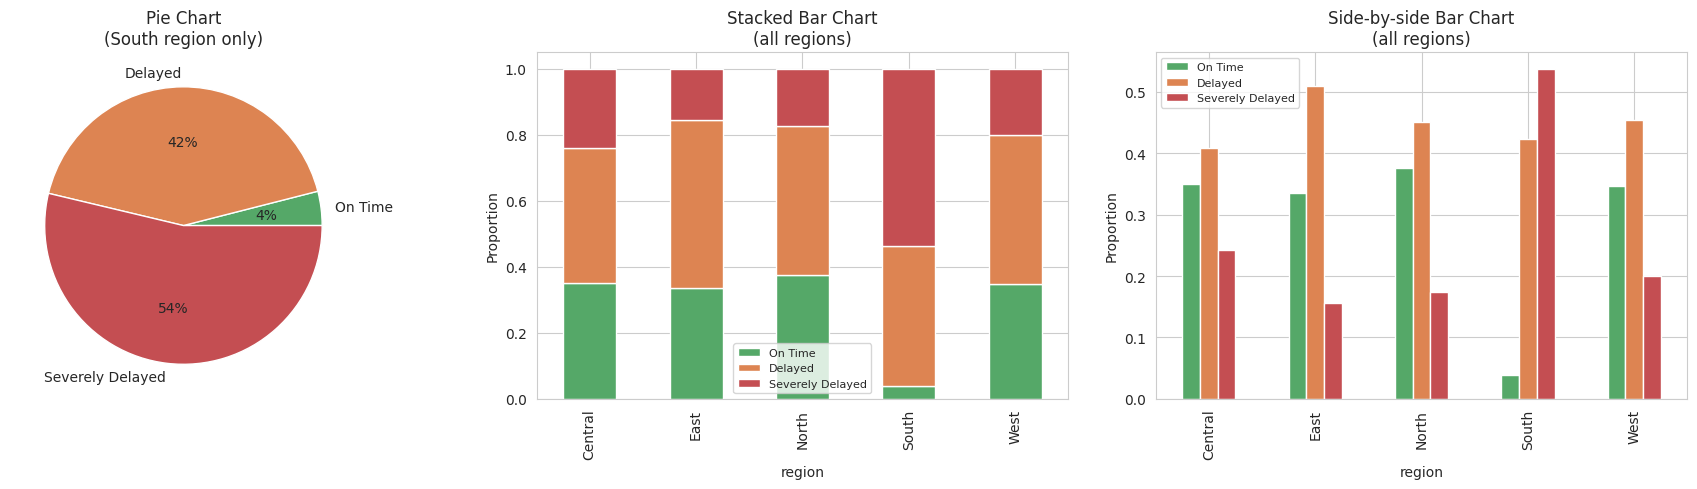

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie chart -- one region only, since pie charts don't compare groups well
axes[0].pie(status_by_region.loc["South"], labels=status_by_region.columns,
            autopct="%1.0f%%", colors=["#55A868", "#DD8452", "#C44E52"])
axes[0].set_title("Pie Chart\n(South region only)")

# Stacked bar -- all regions
status_by_region.plot(kind="bar", stacked=True, ax=axes[1],
                       color=["#55A868", "#DD8452", "#C44E52"])
axes[1].set_title("Stacked Bar Chart\n(all regions)")
axes[1].set_ylabel("Proportion")
axes[1].legend(fontsize=8)

# Side-by-side bar -- all regions
status_by_region.plot(kind="bar", stacked=False, ax=axes[2],
                       color=["#55A868", "#DD8452", "#C44E52"])
axes[2].set_title("Side-by-side Bar Chart\n(all regions)")
axes[2].set_ylabel("Proportion")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Question 3:** Which region has the worst delivery performance, and which chart made
that easiest to spot? Why would the pie chart alone (even one per region) be a poor choice
for comparing all five regions against each other?

*Your answer:* **South** has the worst delivery performance — it has the smallest "On Time"
slice and the largest combined "Delayed" + "Severely Delayed" share of any region. This is
easiest to spot in the **stacked bar chart**, because all five regions sit on a shared
baseline and the eye can compare the "On Time" segment's length across bars directly. The
side-by-side bar chart is a close second, since exact segment heights are easier to compare
than stacked segments, but it uses roughly the same footprint as the stacked version while
losing the "each region sums to 100%" framing. A pie chart, even one per region, would be a
poor choice for comparing all five regions against each other because humans are much worse
at comparing angles/areas across *separate* pies than at comparing bar lengths anchored to
a common baseline — you'd need to mentally re-align five different circles, and any
side-by-side pie layout wastes space without making the comparison any easier to read.


## Wrap-up — Your Recommendation *(~3 min)*

Write a 2–3 sentence recommendation to the QuickCart ops team, combining **both** findings:
- What Task 1 & 2 revealed about delivery time structure (histogram + KDE + bandwidth)
- What Task 3 revealed about regional performance (proportions)

*Your recommendation:* Delivery time isn't one homogeneous process — it's two distinct
services (express and standard) blended together, so any single "average delivery time" KPI
will hide real performance differences between them; ops should track and report on express
and standard deliveries separately rather than as one blended number. Regionally, **South**
is the clear priority for additional delivery staff: it has the highest share of Delayed and
Severely Delayed orders of any region, and this shows up specifically as a rightward shift in
its delivery-time distribution rather than just a handful of outliers, so it looks like a
structural staffing/capacity gap in that region rather than noise.
